# 第7章: 機械学習






In [16]:
# ---- import ----
from collections import Counter
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import numpy as np
import matplotlib
matplotlib.rcParams['font.family'] = 'Hiragino Sans'

DATA_DIR = "SST-2"   # データセットのディレクトリ

## 60. データの入手・整形

`train.tsv`と`dev.tsv`のぞれぞれについて、ポジティブ (1) とネガティブ (0) の事例数をカウントする。

In [6]:
def count_labels(path):
    c = Counter()
    with open(path, encoding="utf-8") as f:
        next(f)  # ヘッダ sentence\tlabel をスキップ
        for line in f:
            label = line.rstrip("\n").split("\t")[1]
            c[label] += 1
    return c

for name in ["train", "dev"]:
    c = count_labels(f"{DATA_DIR}/{name}.tsv")
    print(f"{name}: ポジティブ(1):{c['1']}, ネガティブ(0):{c['0']}, 合計:{sum(c.values())}")

train: ポジティブ(1):37569, ネガティブ(0):29780, 合計:67349
dev: ポジティブ(1):444, ネガティブ(0):428, 合計:872


## 61. 特徴ベクトル

各テキストを BoWで特徴ベクトル化し、
`{'text':..., 'label':..., 'feature':{...}}` の辞書にまとめ、
学習・検証データそれぞれを辞書のリストとして表現する。

In [7]:
def load_dataset(path):
    data = []
    with open(path, encoding="utf-8") as f:
        next(f)  # ヘッダをスキップ
        for line in f:
            text, label = line.rstrip("\n").split("\t")
            feature = dict(Counter(text.split(" ")))  # スペース区切りで頻度カウント
            data.append({"text": text, "label": label, "feature": feature})
    return data

train = load_dataset(f"{DATA_DIR}/train.tsv")
dev   = load_dataset(f"{DATA_DIR}/dev.tsv")

# 学習データの最初の事例を目視確認
train[0]

{'text': 'hide new secretions from the parental units ',
 'label': '0',
 'feature': {'hide': 1,
  'new': 1,
  'secretions': 1,
  'from': 1,
  'the': 1,
  'parental': 1,
  'units': 1,
  '': 1}}

## 62. 学習

61 の特徴ベクトル（辞書）を `DictVectorizer` で数値行列に変換し、
ロジスティック回帰モデルを学習する。

In [8]:
vectorizer = DictVectorizer()
X_train = vectorizer.fit_transform([ex["feature"] for ex in train])
y_train = [ex["label"] for ex in train]

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("学習完了")
print(f"語彙サイズ        : {len(vectorizer.get_feature_names_out())}")
print(f"訓練データ正解率  : {model.score(X_train, y_train):.4f}")

学習完了
語彙サイズ        : 14817
訓練データ正解率  : 0.9422


## 63. 予測

検証データ先頭の事例のラベルを予測し、正解ラベルと一致するか確認する。

In [9]:
ex = dev[0]
X = vectorizer.transform([ex["feature"]])   # 同じ vectorizer で変換 
pred = model.predict(X)[0]

print(f"テキスト   : {ex['text']}")
print(f"予測ラベル : {pred}")
print(f"正解ラベル : {ex['label']}")
print(f"一致      : {pred == ex['label']}")

テキスト   : it 's a charming and often affecting journey . 
予測ラベル : 1
正解ラベル : 1
一致      : True


## 64. 条件付き確率

検証データ先頭の事例を各ラベルに分類するときの条件付き確率を求める。

In [10]:
proba = model.predict_proba(X)[0]   # 63 の X をそのまま使用
classes = model.classes_            # 例: ['0', '1']

for label, p in zip(classes, proba):
    name = "ネガティブ" if label == "0" else "ポジティブ"
    print(f"P(label={label} / {name}) = {p:.4f}")

P(label=0 / ネガティブ) = 0.0042
P(label=1 / ポジティブ) = 0.9958


## 65. テキストのポジネガの予測

与えられたテキストのポジネガを予測するプログラムを実装する。

In [11]:
def predict_text(text):
    feature = dict(Counter(text.split(" ")))      # 61 と同じ特徴量化
    X = vectorizer.transform([feature])           # 同じ vectorizer で変換
    label = model.predict(X)[0]
    proba = dict(zip(model.classes_, model.predict_proba(X)[0]))
    sentiment = "ポジティブ" if label == "1" else "ネガティブ"
    return label, sentiment, proba

text = "the worst movie I 've ever seen"
label, sentiment, proba = predict_text(text)
print(f"テキスト : {text}")
print(f"予測 : {label} ({sentiment})")
print(f"確率 : {{'0': {proba['0']:.4f}, '1': {proba['1']:.4f}}}")

テキスト : the worst movie I 've ever seen
予測 : 0 (ネガティブ)
確率 : {'0': 0.9800, '1': 0.0200}


## 66. 混同行列の作成

学習したロジスティック回帰モデルの検証データにおける混同行列（`confusion matrix`）を求める。

混同行列 (行=正解, 列=予測, 並び=[0,1]):
[[334  94]
 [ 72 372]]


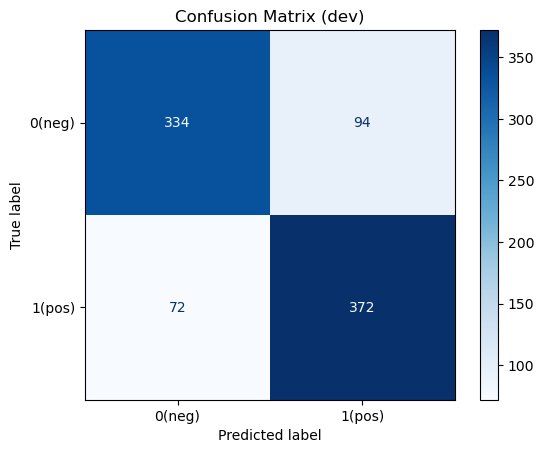

In [12]:
X_dev = vectorizer.transform([ex["feature"] for ex in dev])
y_dev = [ex["label"] for ex in dev]
y_pred = model.predict(X_dev)

cm = confusion_matrix(y_dev, y_pred, labels=["0", "1"])
print("混同行列 (行=正解, 列=予測, 並び=[0,1]):")
print(cm)

ConfusionMatrixDisplay(cm, display_labels=["0(neg)", "1(pos)"]).plot(cmap="Blues")
plt.title("Confusion Matrix (dev)")
plt.show()

## 67. 精度の計測

学習したロジスティック回帰モデルの正解率、適合率、再現率、F1スコアを、学習データおよび検証データ上で計測する。

In [13]:
def evaluate(X, y_true, name):
    y_p = model.predict(X)
    print(f"=== {name} ===")
    print(f"  正解率 (accuracy) : {accuracy_score(y_true, y_p):.4f}")
    print(f"  適合率 (precision): {precision_score(y_true, y_p, pos_label='1'):.4f}")
    print(f"  再現率 (recall)   : {recall_score(y_true, y_p, pos_label='1'):.4f}")
    print(f"  F1スコア          : {f1_score(y_true, y_p, pos_label='1'):.4f}")

evaluate(X_train, y_train, "学習データ")
evaluate(X_dev,   y_dev,   "検証データ")

=== 学習データ ===
  正解率 (accuracy) : 0.9422
  適合率 (precision): 0.9428
  再現率 (recall)   : 0.9542
  F1スコア          : 0.9485
=== 検証データ ===
  正解率 (accuracy) : 0.8096
  適合率 (precision): 0.7983
  再現率 (recall)   : 0.8378
  F1スコア          : 0.8176


## 68. 特徴量の重みの確認

学習したロジスティック回帰モデルの中で、重みの高い特徴量トップ20と、重みの低い特徴量トップ20を確認する。

In [14]:
feature_names = vectorizer.get_feature_names_out()
weights = model.coef_[0]
order = weights.argsort()   # 昇順インデックス

print("=== 重みの高い特徴量トップ20（ポジティブ寄り）===")
for i in order[::-1][:20]:
    print(f"  {weights[i]:+.4f}  {feature_names[i]}")

print("\n=== 重みの低い特徴量トップ20（ネガティブ寄り）===")
for i in order[:20]:
    print(f"  {weights[i]:+.4f}  {feature_names[i]}")

=== 重みの高い特徴量トップ20（ポジティブ寄り）===
  +3.4503  refreshing
  +3.4374  remarkable
  +3.2319  powerful
  +3.1859  hilarious
  +3.0076  beautiful
  +2.9814  wonderful
  +2.8921  prose
  +2.8851  terrific
  +2.8639  appealing
  +2.8380  treat
  +2.8160  enjoyable
  +2.7765  charmer
  +2.7298  vividly
  +2.6956  likable
  +2.6587  solid
  +2.6470  charming
  +2.6095  fascinating
  +2.5994  impressive
  +2.5928  half-bad
  +2.5737  intriguing

=== 重みの低い特徴量トップ20（ネガティブ寄り）===
  -4.3484  lacking
  -4.0766  lacks
  -4.0132  worst
  -3.6691  devoid
  -3.6313  mess
  -3.5935  failure
  -3.3571  stupid
  -3.2736  bore
  -3.2388  flat
  -3.2038  depressing
  -3.1834  loses
  -3.1633  waste
  -3.0625  lack
  -3.0368  squanders
  -3.0220  hardly
  -3.0150  none
  -2.9888  poor
  -2.9839  pointless
  -2.9587  unfortunately
  -2.9547  lousy


## 69. 正則化パラメータの変更

ロジスティック回帰モデルを学習するとき、正則化の係数（`ハイパーパラメータ`）を調整することで、学習時の適合度合いを制御できる。正則化の係数を変化させながらロジスティック回帰モデルを学習し、検証データ上の正解率を求めよ。実験の結果は、正則化パラメータを横軸、正解率を縦軸としたグラフにまとめる。

C=  0.0010  dev正解率=0.6800
C=  0.0028  dev正解率=0.7053
C=  0.0081  dev正解率=0.7477
C=  0.0231  dev正解率=0.7844
C=  0.0658  dev正解率=0.8016
C=  0.1874  dev正解率=0.8073
C=  0.5337  dev正解率=0.8028
C=  1.5199  dev正解率=0.8119
C=  4.3288  dev正解率=0.8177
C= 12.3285  dev正解率=0.8211
C= 35.1119  dev正解率=0.8096
C=100.0000  dev正解率=0.7959


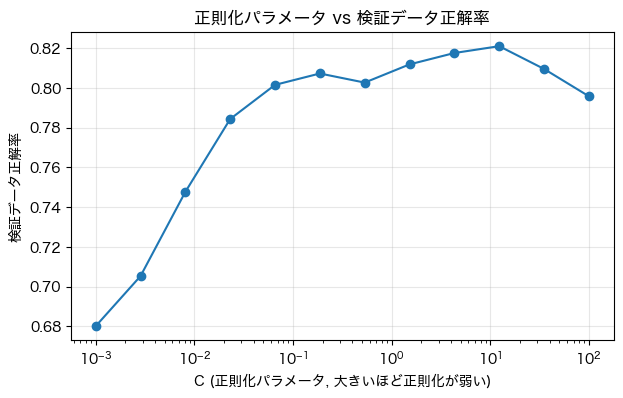

In [17]:
C_values = np.logspace(-3, 2, 12)   # 0.001 〜 100 を対数的に12点
dev_acc = []
for C in C_values:
    m = LogisticRegression(max_iter=1000, C=C)
    m.fit(X_train, y_train)
    acc = m.score(X_dev, y_dev)
    dev_acc.append(acc)
    print(f"C={C:8.4f}  dev正解率={acc:.4f}")

plt.figure(figsize=(7, 4))
plt.semilogx(C_values, dev_acc, marker="o")
plt.xlabel("C (正則化パラメータ, 大きいほど正則化が弱い)")
plt.ylabel("検証データ正解率")
plt.title("正則化パラメータ vs 検証データ正解率")
plt.grid(True, alpha=0.3)
plt.show()